<a href="https://colab.research.google.com/github/farid24ti/probstat-python-eksplorasi/blob/main/03_jenis_jenis_distribusi_probabilitas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Jenis-Jenis Distribusi Probabilitas dengan Python

Notebook ini memuat distribusi probabilitas diskrit dan kontinu, serta variabel acak gabungan, aproksimasi, dan Teorema Limit Pusat. Setiap soal menghitung probabilitas, nilai harapan, varians, simulasi, dan visualisasi pada studi kasus bidang Teknik Informatika.

## Daftar isi

| Bab | Isi |
|---|---|
| 1 | Distribusi Probabilitas Diskrit |
| 2 | Distribusi Probabilitas Kontinu |
| 3 | Variabel Acak, Teorema Limit Pusat, dan Aproksimasi Distribusi |

---
# Bab 1: Distribusi Probabilitas Diskrit

Distribusi yang dibahas: Uniform Diskrit, Bernoulli, Binomial, Geometrik, Binomial Negatif, Hipergeometrik, Poisson, dan Multinomial. Setiap soal menghitung probabilitas, nilai harapan, varians, simulasi, dan visualisasi.

## Ringkasan distribusi

| Distribusi | Situasi | pmf | E(X) | Var(X) | `scipy.stats` |
|---|---|---|---|---|---|
| Uniform diskrit | Semua nilai a..b sama mungkin | 1/(b−a+1) | (a+b)/2 | ((b−a+1)²−1)/12 | `randint(a, b+1)` |
| Bernoulli | Satu percobaan, sukses/gagal | pˣ(1−p)¹⁻ˣ | p | p(1−p) | `bernoulli(p)` |
| Binomial | Jumlah sukses dalam n percobaan | C(n,x)pˣ(1−p)ⁿ⁻ˣ | np | np(1−p) | `binom(n, p)` |
| Geometrik | Percobaan ke-berapa sukses pertama | (1−p)ˣ⁻¹p | 1/p | (1−p)/p² | `geom(p)` |
| Binomial negatif | Percobaan ke-berapa sukses ke-r | C(x−1,r−1)pʳ(1−p)ˣ⁻ʳ | r/p | r(1−p)/p² | `nbinom(r, p)` (menghitung kegagalan) |
| Hipergeometrik | Sampel tanpa pengembalian | C(k,x)C(N−k,n−x)/C(N,n) | nk/N | n(k/N)(1−k/N)(N−n)/(N−1) | `hypergeom(N, k, n)` |
| Poisson | Jumlah kejadian per selang | λˣ·e^(−λ)/x! | λ | λ | `poisson(λ)` |
| Multinomial | Hasil >2 kategori dalam n percobaan | n!/(x₁!…xₖ!) Πpᵢˣⁱ | npᵢ | npᵢ(1−pᵢ) | `multinomial(n, p)` |

Catatan: pada tabel, rumus Poisson adalah λˣ e^(−λ) / x!. Rumus varians hipergeometrik pada slide modul tertulis kurang tepat; yang dipakai di sini adalah rumus yang benar.

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
rng = np.random.default_rng(42)

def batang(x, p, judul, xlabel="x", warna="steelblue"):
    plt.figure(figsize=(6.5, 3.3))
    plt.bar(x, p, color=warna)
    plt.title(judul); plt.xlabel(xlabel); plt.ylabel("P(X = x)")
    plt.show()

## Soal 1.1: Uniform diskrit: load balancer

**Studi kasus:** Sebuah load balancer memilih salah satu dari 6 server (nomor 1 sampai 6) dengan peluang sama untuk setiap permintaan.

**Ditanyakan:** Berapa P(X = 3), nilai harapan, dan varians nomor server yang terpilih?

**Konsep / rumus:** pmf = 1/6; E(X) = (1+6)/2; Var(X) = (6² − 1)/12.

**Perhitungan manual:** E(X) = 3,5; Var(X) = 35/12 ≈ 2,9167.

P(X=3)    : 0.1667
E(X)      : 3.5 | rumus (a+b)/2 = 3.5
Var(X)    : 2.9167 | rumus ((b-a+1)^2-1)/12 = 2.9167
Simulasi  : mean = 3.501 | var = 2.916


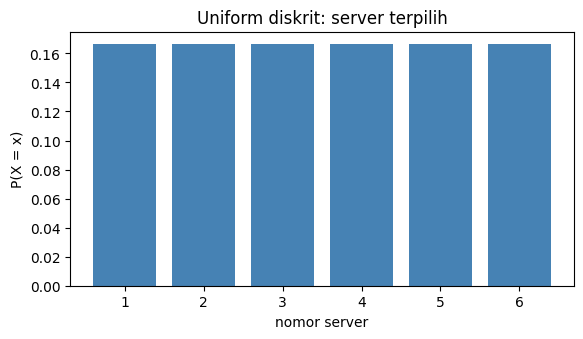

In [2]:
d = stats.randint(1, 7)                # nilai 1..6
print("P(X=3)    :", round(d.pmf(3), 4))
print("E(X)      :", d.mean(), "| rumus (a+b)/2 =", (1 + 6) / 2)
print("Var(X)    :", round(d.var(), 4), "| rumus ((b-a+1)^2-1)/12 =", round((6**2 - 1) / 12, 4))

sampel = d.rvs(size=200_000, random_state=42)
print("Simulasi  : mean =", round(sampel.mean(), 3), "| var =", round(sampel.var(), 3))
batang(np.arange(1, 7), d.pmf(np.arange(1, 7)), "Uniform diskrit: server terpilih", "nomor server")

**Interpretasi:** Setiap server dipilih dengan peluang 1/6 ≈ 0,1667, dan nomor rata-rata yang terpilih 3,5 (tidak harus nilai yang mungkin muncul). Rumus dan simulasi sama. Histogram yang datar menunjukkan beban terbagi merata dalam jangka panjang; jika histogram hasil pengamatan nyata tidak datar, berarti load balancer tidak seimbang.

## Soal 1.2: Bernoulli: satu permintaan sukses atau gagal

**Studi kasus:** Sebuah endpoint API berhasil memproses permintaan dengan peluang 0,9.

**Ditanyakan:** Tentukan P(X = 1), P(X = 0), nilai harapan, dan varians dari X (1 = sukses, 0 = gagal).

**Konsep / rumus:** pmf: P(X=1) = p, P(X=0) = 1−p; E(X) = p; Var(X) = p(1−p).

**Perhitungan manual:** E(X) = 0,9; Var(X) = 0,9 × 0,1 = 0,09.

In [3]:
p = 0.9
b = stats.bernoulli(p)
print("P(X=1) =", b.pmf(1), "| P(X=0) =", round(b.pmf(0), 2))
print("E(X)   =", b.mean(), "| Var(X) =", round(b.var(), 4), "| rumus p(1-p) =", round(p * (1 - p), 4))
x = b.rvs(size=200_000, random_state=1)
print("Simulasi: proporsi sukses =", round(x.mean(), 4), "| var =", round(x.var(), 4))

P(X=1) = 0.9 | P(X=0) = 0.1
E(X)   = 0.9 | Var(X) = 0.09 | rumus p(1-p) = 0.09
Simulasi: proporsi sukses = 0.9 | var = 0.09


**Interpretasi:** Nilai harapan 0,9 sama dengan peluang sukses (untuk variabel 0/1, rata-rata adalah proporsi). Varians 0,09 kecil karena hasil hampir selalu sukses; varians maksimum 0,25 terjadi pada p = 0,5. Bernoulli adalah blok pembangun distribusi Binomial, Geometrik, dan Binomial Negatif.

## Soal 1.3: Binomial: pemilihan kegiatan (contoh modul) dan paket data hilang

**Studi kasus:** (a) Setiap tahun selama 5 tahun, satu dari 4 kegiatan dipilih acak untuk mendapat dana (p = 0,25 untuk kegiatan A). (b) Dalam transmisi, tiap paket data hilang dengan peluang 0,1 secara independen; dikirim 10 paket.

**Ditanyakan:** (a) Berapa P(A mendapat dana tepat 3 kali) dan seluruh distribusinya, beserta mean, varians, dan skewness? (b) Berapa peluang minimal 2 paket hilang?

**Konsep / rumus:** f(x) = C(n,x) pˣ (1−p)ⁿ⁻ˣ; E = np; Var = npq; skewness = (q−p)/√(npq).

**Perhitungan manual:** (a) f(3) = C(5,3)(0,25)³(0,75)² = 10 × 0,015625 × 0,5625 = 0,0879. (b) P(X ≥ 2) = 1 − P(0) − P(1) = 1 − 0,3487 − 0,3874 = 0,2639.

Manual f(3)   : 0.0879 | scipy: 0.0879
 x  jumlah cara  P(X=x)
 0            1  0.2373
 1            5  0.3955
 2           10  0.2637
 3           10  0.0879
 4            5  0.0146
 5            1  0.0010
Jumlah probabilitas: 1.0
E = 1.25 (np = 1.25) | Var = 0.9375 (npq = 0.9375) | skewness = 0.5164 (rumus 0.5164)


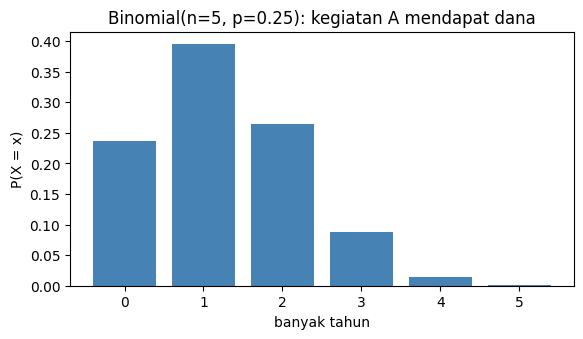


(b) P(minimal 2 paket hilang dari 10) = 0.2639 | 1 - cdf(1) = 0.2639
    Simulasi: 0.2643


In [4]:
# (a) contoh modul
n, p = 5, 0.25
x = np.arange(0, n + 1)
pmf = stats.binom.pmf(x, n, p)
print("Manual f(3)   :", round(math.comb(5, 3) * 0.25**3 * 0.75**2, 4), "| scipy:", round(stats.binom.pmf(3, 5, 0.25), 4))
print(pd.DataFrame({"x": x, "jumlah cara": [math.comb(n, i) for i in x], "P(X=x)": pmf.round(4)}).to_string(index=False))
print("Jumlah probabilitas:", round(pmf.sum(), 4))
m, v, s = stats.binom.stats(n, p, moments="mvs")
print(f"E = {m} (np = {n*p}) | Var = {v} (npq = {n*p*(1-p)}) | skewness = {float(s):.4f} (rumus {(0.75-0.25)/math.sqrt(n*p*0.75):.4f})")
batang(x, pmf, "Binomial(n=5, p=0.25): kegiatan A mendapat dana", "banyak tahun")

# (b) paket hilang
print("\n(b) P(minimal 2 paket hilang dari 10) =", round(stats.binom.sf(1, 10, 0.1), 4), "| 1 - cdf(1) =", round(1 - stats.binom.cdf(1, 10, 0.1), 4))
sim = rng.binomial(10, 0.1, size=300_000)
print("    Simulasi:", round(np.mean(sim >= 2), 4))

**Interpretasi:** (a) Kegiatan A paling mungkin mendapat dana 1 kali (0,3955); mendapat dana 3 kali hanya 0,0879 dan 5 kali hanya 0,001. Semua probabilitas berjumlah 1 dan angkanya sama dengan tabel modul. Skewness positif (0,516) karena p < 0,5, sehingga distribusi miring ke kanan. (b) Dengan 10 paket dan laju hilang 10%, peluang minimal 2 paket hilang adalah 0,2639 (sekitar 26%); jadi hampir seperempat pengiriman mengalami 2 paket hilang atau lebih, yang menunjukkan perlunya mekanisme pengiriman ulang (retransmisi). Simulasi mendukung hasil rumus.

## Soal 1.4: Geometrik: percobaan sampai sukses pertama

**Studi kasus:** Seorang penguji keamanan mencoba login dengan password acak; tiap percobaan berhasil dengan peluang 0,2 (independen).

**Ditanyakan:** Berapa peluang sukses pertama terjadi tepat pada percobaan ke-3, peluang sukses dalam 5 percobaan pertama, dan rata-rata percobaan sampai sukses?

**Konsep / rumus:** f(x) = (1−p)ˣ⁻¹ p; E(X) = 1/p; Var(X) = (1−p)/p².

**Perhitungan manual:** f(3) = 0,8² × 0,2 = 0,128. P(X ≤ 5) = 1 − 0,8⁵ = 0,6723. E(X) = 5; Var(X) = 20.

P(X=3)  manual: 0.128 | scipy: 0.128
P(X<=5) manual: 0.6723 | scipy: 0.6723
E(X)    = 5.0 | Var(X) = 20.0
Simulasi: mean = 5.013 | var = 20.22


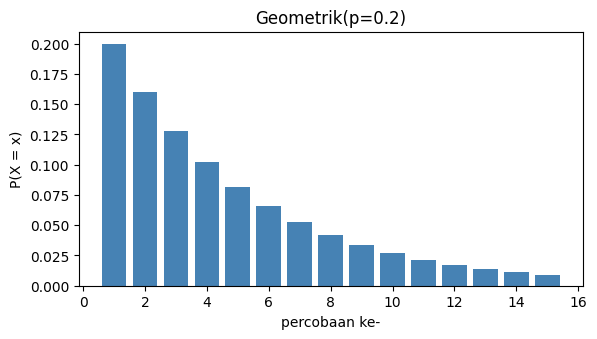

In [5]:
p = 0.2
g = stats.geom(p)
print("P(X=3)  manual:", round((1 - p)**2 * p, 4), "| scipy:", round(g.pmf(3), 4))
print("P(X<=5) manual:", round(1 - (1 - p)**5, 4), "| scipy:", round(g.cdf(5), 4))
print("E(X)    =", g.mean(), "| Var(X) =", g.var())
sim = g.rvs(size=300_000, random_state=3)
print("Simulasi: mean =", round(sim.mean(), 3), "| var =", round(sim.var(), 2))
x = np.arange(1, 16)
batang(x, g.pmf(x), "Geometrik(p=0.2)", "percobaan ke-")

**Interpretasi:** Sukses pertama paling mungkin terjadi pada percobaan pertama (peluang 0,2) dan peluang menurun terus ke kanan. Ada 67% peluang sukses dalam 5 percobaan, dan rata-rata dibutuhkan 5 percobaan. Varians besar (20), artinya waktu sampai sukses sangat bervariasi. Dari sisi keamanan, peluang 0,2 per tebakan terlalu longgar; pembatasan jumlah percobaan login perlu untuk menekan peluang ini.

## Soal 1.5: Binomial negatif: percobaan sampai sukses ke-r

**Studi kasus:** Sebuah proses memerlukan 3 permintaan sukses; tiap permintaan sukses dengan peluang 0,6 (independen).

**Ditanyakan:** Berapa peluang total tepat 5 permintaan diperlukan untuk mendapat 3 sukses, peluang selesai dalam 5 permintaan atau kurang, dan rata-rata permintaan yang dibutuhkan?

**Konsep / rumus:** f(x; r, p) = C(x−1, r−1) pʳ (1−p)ˣ⁻ʳ; E = r/p; Var = r(1−p)/p². Dalam scipy, `nbinom` menghitung banyak kegagalan (x − r).

**Perhitungan manual:** f(5) = C(4,2)(0,6)³(0,4)² = 6 × 0,216 × 0,16 = 0,2074. E = 3/0,6 = 5; Var = 3 × 0,4 / 0,36 = 3,3333.

P(tepat 5 percobaan) manual: 0.2074 | scipy: 0.2074
P(<= 5 percobaan)           : 0.6826
E(percobaan) = E(gagal)+r   : 5.0 | rumus r/p = 5.0
Var(percobaan)              : 3.3333 | rumus = 3.3333
Simulasi: mean = 4.995 | var = 3.322


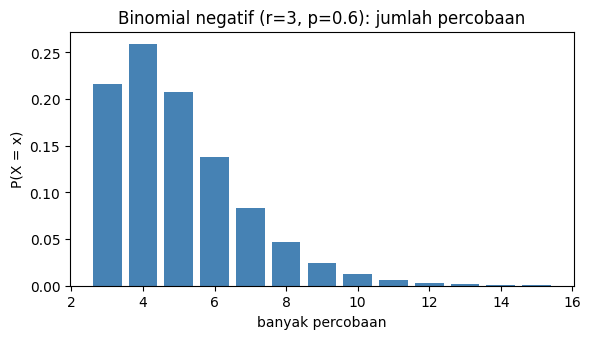

In [6]:
r, p = 3, 0.6
nb = stats.nbinom(r, p)                     # menghitung KEGAGALAN sebelum sukses ke-r
print("P(tepat 5 percobaan) manual:", round(math.comb(4, 2) * p**3 * (1 - p)**2, 4), "| scipy:", round(nb.pmf(5 - r), 4))
print("P(<= 5 percobaan)           :", round(nb.cdf(5 - r), 4))
print("E(percobaan) = E(gagal)+r   :", nb.mean() + r, "| rumus r/p =", r / p)
print("Var(percobaan)              :", round(nb.var(), 4), "| rumus =", round(r * (1 - p) / p**2, 4))
sim = nb.rvs(size=300_000, random_state=5) + r
print("Simulasi: mean =", round(sim.mean(), 3), "| var =", round(sim.var(), 3))
x = np.arange(r, 16)
batang(x, nb.pmf(x - r), "Binomial negatif (r=3, p=0.6): jumlah percobaan", "banyak percobaan")

**Interpretasi:** Jika dibutuhkan 3 sukses, banyak percobaan paling mungkin adalah 3 atau 4. Peluang tepat 5 percobaan 0,2074 dan peluang selesai dalam 5 percobaan atau kurang 0,6826 (sekitar 68%). Rata-rata 5 percobaan. Perhatikan konversi `nbinom` di scipy yang menghitung kegagalan; jika lupa menambah r, hasil mean akan salah. Untuk r = 1, distribusi ini sama dengan geometrik.

## Soal 1.6: Hipergeometrik (contoh modul): audit server tanpa pengembalian

**Studi kasus:** Sebuah pusat data memiliki 12 server, 2 di antaranya rusak. Manajemen memilih 6 server acak untuk diaudit (tanpa pengembalian).

**Ditanyakan:** Berapa peluang server rusak yang terpilih berjumlah 0, 1, atau 2? Hitung juga nilai harapan dan varians, lalu bandingkan dengan binomial (jika dianggap dengan pengembalian).

**Konsep / rumus:** f(x) = C(k,x) C(N−k, n−x) / C(N,n); E = nk/N; Var = n·k·(N−k)·(N−n) / (N²(N−1)).

**Perhitungan manual:** f(0) = C(10,6)/C(12,6) = 210/924 = 0,2273; f(1) = 2 × 252/924 = 0,5455; f(2) = C(10,4)/924 = 0,2273. E = 1; Var = 6·2·10·6 / (144·11) = 0,4545.

 x  manual  scipy  binomial (keliru)
 0  0.2273 0.2273             0.3349
 1  0.5455 0.5455             0.4019
 2  0.2273 0.2273             0.2009

E(X) : 1.0 | rumus nk/N = 1.0
Var  : 0.4545 | rumus benar = 0.4545 | varians binomial = 0.8333
Simulasi: mean = 1.0 | var = 0.456


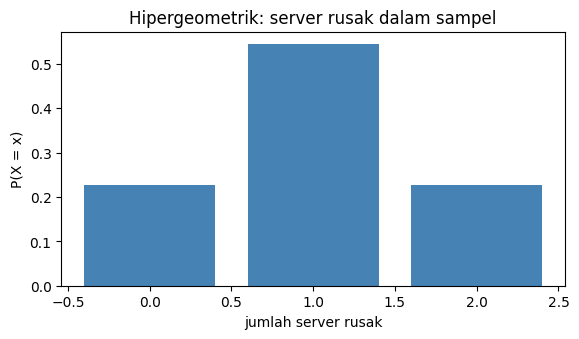

In [7]:
N, k, n = 12, 2, 6
h = stats.hypergeom(M=N, n=k, N=n)          # M=populasi, n=jumlah 'sukses' (rusak), N=ukuran sampel
x = np.arange(0, 3)
manual = [math.comb(k, i) * math.comb(N - k, n - i) / math.comb(N, n) for i in x]
tabel = pd.DataFrame({"x": x, "manual": np.round(manual, 4), "scipy": h.pmf(x).round(4),
                      "binomial (keliru)": stats.binom.pmf(x, n, k / N).round(4)})
print(tabel.to_string(index=False))
print("\nE(X) :", h.mean(), "| rumus nk/N =", n * k / N)
print("Var  :", round(h.var(), 4), "| rumus benar =", round(n * k * (N - k) * (N - n) / (N**2 * (N - 1)), 4),
      "| varians binomial =", round(n * (k / N) * (1 - k / N), 4))
sim = h.rvs(size=300_000, random_state=6)
print("Simulasi: mean =", round(sim.mean(), 3), "| var =", round(sim.var(), 3))
batang(x, h.pmf(x), "Hipergeometrik: server rusak dalam sampel", "jumlah server rusak")

**Interpretasi:** Peluang audit tidak menemukan server rusak sama sekali adalah 0,2273, dan peluang menemukan keduanya juga 0,2273; paling mungkin ditemukan 1 server rusak (0,5455). Jumlah ketiga peluang = 1. Rata-rata temuan = 1 server rusak per audit. Varians hipergeometrik (0,4545) lebih kecil dari varians binomial (0,8333) karena pengambilan tanpa pengembalian menyempitkan kemungkinan hasil; menggunakan binomial pada kasus ini akan menaksir peluang secara keliru (misalnya P(X=2) menjadi 0,2009). Binomial baru hampir sama dengan hipergeometrik jika populasi jauh lebih besar dari sampel.

## Soal 1.7: Poisson: error log per menit

**Studi kasus:** Sebuah server mencatat rata-rata 2 error per menit secara acak dan independen.

**Ditanyakan:** Berapa peluang tepat 1 error dalam semenit, tepat 0 error, dan minimal 3 error? Berapa peluang lebih dari 15 error dalam 5 menit?

**Konsep / rumus:** f(x) = λˣ e⁻λ / x!; E = Var = λ. Untuk selang lebih panjang, λ dikalikan panjang selang (5 menit → λ = 10).

**Perhitungan manual:** f(1) = 2e⁻² = 0,2707; f(0) = e⁻² = 0,1353.

P(X=1) manual: 0.2707 | scipy: 0.2707
P(X=0)       : 0.1353
P(X>=3)      : 0.3233 | 1 - cdf(2) = 0.3233
E = Var      : 2.0 2.0
Selang 5 menit (lambda=10): P(X>15) = 0.0487
Simulasi 1 menit: mean = 2.001 | var = 1.996


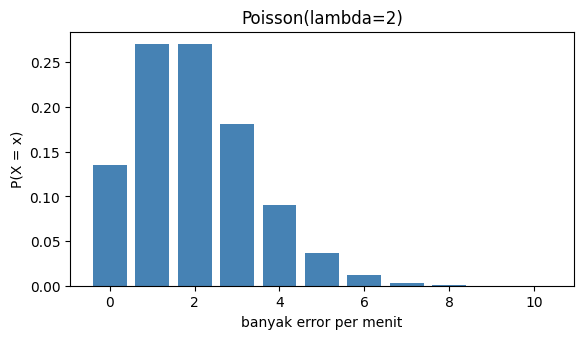

In [8]:
lam = 2
po = stats.poisson(lam)
print("P(X=1) manual:", round(lam * math.exp(-lam), 4), "| scipy:", round(po.pmf(1), 4))
print("P(X=0)       :", round(po.pmf(0), 4))
print("P(X>=3)      :", round(po.sf(2), 4), "| 1 - cdf(2) =", round(1 - po.cdf(2), 4))
print("E = Var      :", po.mean(), po.var())
print("Selang 5 menit (lambda=10): P(X>15) =", round(stats.poisson.sf(15, 10), 4))
sim = po.rvs(size=300_000, random_state=7)
print("Simulasi 1 menit: mean =", round(sim.mean(), 3), "| var =", round(sim.var(), 3))
x = np.arange(0, 11)
batang(x, po.pmf(x), "Poisson(lambda=2)", "banyak error per menit")

**Interpretasi:** Peluang tepat 1 error per menit adalah 0,2707, dan tanpa error sama sekali 0,1353 (sekitar 13,5% menit bebas error). Peluang minimal 3 error dalam semenit adalah 0,3233; jadi hampir sepertiga menit mengalami lonjakan 3 error atau lebih, relevan untuk menetapkan ambang alarm. Dalam 5 menit, lebih dari 15 error hanya berpeluang sekitar 4,9%, sehingga bila ini terjadi, patut dicurigai ada masalah yang tidak acak. Mean dan varians simulasi sama-sama mendekati 2, sesuai sifat Poisson (E = Var). Jika varians data nyata jauh lebih besar dari rata-ratanya (overdispersion), model Poisson tidak cocok.

## Soal 1.8: Multinomial: jenis permintaan HTTP

**Studi kasus:** Sebuah server menerima 3 jenis permintaan: GET (0,6), POST (0,3), dan DELETE (0,1), saling independen. Dalam 10 permintaan:

**Ditanyakan:** Berapa peluang tepat 6 GET, 3 POST, dan 1 DELETE? Berapa nilai harapan tiap jenis dan kovarians antara GET dan POST?

**Konsep / rumus:** f(x₁,x₂,x₃) = n!/(x₁! x₂! x₃!) · p₁ˣ¹ p₂ˣ² p₃ˣ³; E(Xᵢ) = npᵢ; Cov(Xᵢ,Xⱼ) = −npᵢpⱼ.

**Perhitungan manual:** 10!/(6!3!1!) = 840; peluang = 840 × 0,6⁶ × 0,3³ × 0,1 = 0,1058. E = (6, 3, 1); Cov(GET,POST) = −10 × 0,6 × 0,3 = −1,8.

In [9]:
n, pk = 10, [0.6, 0.3, 0.1]
mn = stats.multinomial(n, pk)
x = [6, 3, 1]
koef = math.factorial(10) // (math.factorial(6) * math.factorial(3) * math.factorial(1))
manual = koef * 0.6**6 * 0.3**3 * 0.1**1
print("Koefisien multinomial:", koef)
print("P(6,3,1) manual:", round(manual, 4), "| scipy:", round(mn.pmf(x), 4))
print("E per jenis    :", [n * p for p in pk])
sim = rng.multinomial(n, pk, size=300_000)
print("Simulasi mean  :", sim.mean(axis=0).round(3))
print("Cov(GET,POST)  : teori =", round(-n * 0.6 * 0.3, 2), "| simulasi =", round(np.cov(sim[:, 0], sim[:, 1])[0, 1], 3))
print("Simulasi P(6,3,1):", round(np.mean((sim == x).all(axis=1)), 4))

Koefisien multinomial: 840
P(6,3,1) manual: 0.1058 | scipy: 0.1058
E per jenis    : [6.0, 3.0, 1.0]
Simulasi mean  : [6.    2.998 1.001]
Cov(GET,POST)  : teori = -1.8 | simulasi = -1.796
Simulasi P(6,3,1): 0.1065


**Interpretasi:** Peluang komposisi tepat 6 GET, 3 POST, dan 1 DELETE adalah 0,1058 (sekitar 10,6%), yang merupakan komposisi paling mungkin, namun tetap hanya terjadi sekitar 1 dari 10 kali karena banyak komposisi lain yang mungkin. Rata-rata tiap jenis sesuai npᵢ. Kovarians antara GET dan POST negatif (−1,8) karena jumlah total tetap 10: jika GET bertambah, jenis lain harus berkurang. Hasil simulasi cocok dengan rumus.

## Kesimpulan Bab 1

Pemilihan distribusi bergantung pada struktur situasi: satu percobaan (Bernoulli), jumlah sukses dalam n percobaan (Binomial), waktu hingga sukses pertama atau ke-r (Geometrik/Binomial Negatif), sampel tanpa pengembalian (Hipergeometrik), kejadian per selang (Poisson), dan banyak kategori (Multinomial). Dalam semua soal, rumus manual, `scipy.stats`, dan simulasi menghasilkan angka yang konsisten.

---
# Bab 2: Distribusi Probabilitas Kontinu

Distribusi yang dibahas: Uniform, Normal (dan normal standar), Eksponensial, Gamma, t-Student, Chi-kuadrat, F, serta tambahan Beta, Log-normal, dan Weibull. Pada distribusi kontinu, probabilitas adalah **luas di bawah kurva pdf**; P(X = x) selalu 0.

## Ringkasan distribusi

| Distribusi | Kegunaan | E(X) | Var(X) | `scipy.stats` |
|---|---|---|---|---|
| Uniform(a, b) | Semua nilai dalam rentang sama mungkin | (a+b)/2 | (b−a)²/12 | `uniform(loc=a, scale=b-a)` |
| Normal(μ, σ²) | Data simetris berbentuk lonceng | μ | σ² | `norm(loc, scale)` |
| Eksponensial(λ) | Waktu antar kejadian Poisson | 1/λ | 1/λ² | `expon(scale=1/λ)` |
| Gamma(r, λ) | Waktu sampai kejadian ke-r | r/λ | r/λ² | `gamma(a=r, scale=1/λ)` |
| t-Student(ν) | Inferensi rata-rata sampel kecil | 0 (ν>1) | ν/(ν−2) (ν>2) | `t(df)` |
| Chi-kuadrat(ν) | Uji kecocokan/independensi | ν | 2ν | `chi2(df)` |
| F(ν₁, ν₂) | Perbandingan dua varians | ν₂/(ν₂−2) | rumus panjang | `f(dfn, dfd)` |
| Beta(a, b) | Peluang yang tidak diketahui (0–1) | a/(a+b) | ab/((a+b)²(a+b+1)) | `beta(a, b)` |
| Log-normal | Data positif miring ke kanan | exp(μ+σ²/2) | — | `lognorm(s=σ, scale=exp(μ))` |
| Weibull | Umur/keandalan | scale·Γ(1+1/c) | — | `weibull_min(c, scale)` |

Fungsi penting: `.pdf(x)` (kepadatan), `.cdf(x)` (P(X ≤ x)), `.sf(x)` (P(X > x) = 1 − cdf), `.ppf(q)` (kuantil, kebalikan cdf).

In [10]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
rng = np.random.default_rng(42)

## Soal 2.1: Uniform kontinu: waktu tunggu antrean

**Studi kasus:** Waktu tunggu seorang pengguna di antrean layanan bantuan tersebar merata antara 0 dan 10 menit.

**Ditanyakan:** Hitung P(X < 3), P(2 < X < 6), nilai harapan, dan varians waktu tunggu.

**Konsep / rumus:** pdf = 1/(b−a) = 0,1 pada [0, 10]; P(c < X < d) = (d−c)/(b−a); E = (a+b)/2; Var = (b−a)²/12.

**Perhitungan manual:** P(X<3) = 3/10 = 0,3; P(2<X<6) = 4/10 = 0,4; E = 5; Var = 100/12 ≈ 8,3333.

P(X<3)     : 0.3
P(2<X<6)   : 0.4
E(X), Var  : 5.0 8.3333 | rumus (b-a)^2/12 = 8.3333
Simulasi   : P(X<3) = 0.3013 | mean = 4.997


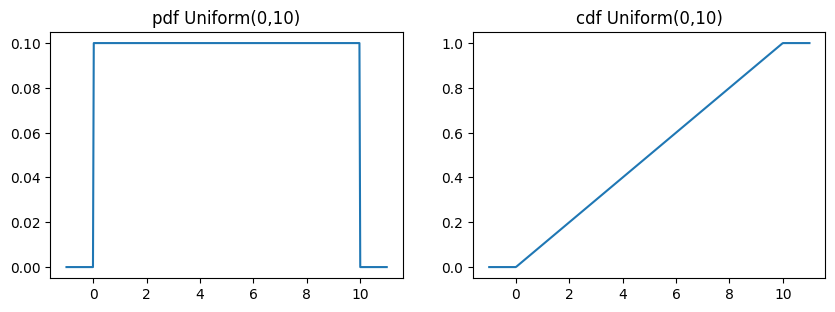

In [11]:
u = stats.uniform(loc=0, scale=10)
print("P(X<3)     :", round(u.cdf(3), 4))
print("P(2<X<6)   :", round(u.cdf(6) - u.cdf(2), 4))
print("E(X), Var  :", u.mean(), round(u.var(), 4), "| rumus (b-a)^2/12 =", round(100 / 12, 4))
s = u.rvs(size=300_000, random_state=1)
print("Simulasi   : P(X<3) =", round(np.mean(s < 3), 4), "| mean =", round(s.mean(), 3))

x = np.linspace(-1, 11, 400)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(x, u.pdf(x)); ax[0].set_title("pdf Uniform(0,10)")
ax[1].plot(x, u.cdf(x)); ax[1].set_title("cdf Uniform(0,10)")
plt.show()

**Interpretasi:** Peluang menunggu kurang dari 3 menit adalah 0,3 (30%) dan antara 2 sampai 6 menit adalah 0,4 (40%). Rata-rata waktu tunggu 5 menit. Kurva pdf datar (0,1) karena semua waktu sama mungkin, dan cdf naik linear. Jika data antrean nyata tidak merata (misalnya lebih banyak yang menunggu singkat), model uniform tidak cocok.

## Soal 2.2: Normal (contoh modul): waktu respons API

**Studi kasus:** Waktu respons sebuah API berdistribusi normal dengan rata-rata 12 ms dan simpangan baku 3 ms.

**Ditanyakan:** Hitung P(X < 15), P(X < 9), P(9 < X < 15), P(X > 18), dan waktu respons x sehingga P(X < x) = 0,8.

**Konsep / rumus:** Standarisasi Z = (X − μ)/σ, lalu cari luas di bawah kurva normal standar (cdf). Kebalikannya memakai ppf.

**Perhitungan manual:** P(X<15) = P(Z<1) = 0,8413; P(X<9) = P(Z<−1) = 0,1587; P(9<X<15) = 0,8413 − 0,1587 = 0,6827.

P(X<15)       : 0.8413 | lewat Z: 0.8413
P(X<9)        : 0.1587
P(9<X<15)     : 0.6827
P(X>18)       : 0.0228
x utk P=0.8   : 14.5249 ms
pdf di x=12   : 0.133 (kepadatan, bukan peluang) | P(X=12) = 0


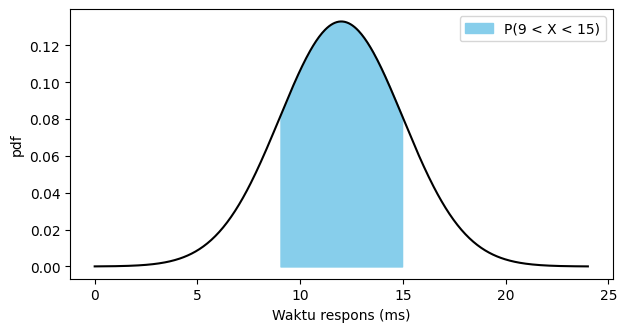

In [12]:
mu, sigma = 12, 3
nd = stats.norm(mu, sigma)
print("P(X<15)       :", round(nd.cdf(15), 4), "| lewat Z:", round(stats.norm.cdf((15 - mu) / sigma), 4))
print("P(X<9)        :", round(nd.cdf(9), 4))
print("P(9<X<15)     :", round(nd.cdf(15) - nd.cdf(9), 4))
print("P(X>18)       :", round(nd.sf(18), 4))
print("x utk P=0.8   :", round(nd.ppf(0.8), 4), "ms")
print("pdf di x=12   :", round(nd.pdf(12), 4), "(kepadatan, bukan peluang) | P(X=12) = 0")

x = np.linspace(0, 24, 500)
plt.figure(figsize=(7, 3.5))
plt.plot(x, nd.pdf(x), color="black")
mask = (x >= 9) & (x <= 15)
plt.fill_between(x[mask], nd.pdf(x[mask]), color="skyblue", label="P(9 < X < 15)")
plt.xlabel("Waktu respons (ms)"); plt.ylabel("pdf"); plt.legend(); plt.show()

**Interpretasi:** Sekitar 84% respons selesai dalam kurang dari 15 ms dan sekitar 68% berada antara 9 dan 15 ms (±1 simpangan baku dari rata-rata). Respons lebih lambat dari 18 ms hanya sekitar 2,3%. Jika SLA menuntut 80% respons lebih cepat dari batas tertentu, batasnya sekitar 14,52 ms. Angka-angka ini sama dengan contoh modul (0,8413 dan 14,5249). Nilai pdf (0,133) adalah kepadatan, bukan peluang; peluang titik tunggal P(X = 12) = 0.

## Soal 2.3: Aturan 68-95-99,7 dan z-score untuk mendeteksi anomali

**Studi kasus:** Dengan waktu respons API seperti Soal 2.2 (μ = 12, σ = 3), sebuah respons tercatat 20 ms.

**Ditanyakan:** Verifikasi aturan 68-95-99,7, hitung z-score 20 ms, dan peluang respons selambat itu atau lebih.

**Konsep / rumus:** z = (x − μ)/σ; peluang dalam ±kσ dari rata-rata = cdf(k) − cdf(−k).

**Perhitungan manual:** z = (20 − 12)/3 ≈ 2,67.

In [13]:
for k in [1, 2, 3]:
    p = stats.norm.cdf(k) - stats.norm.cdf(-k)
    print(f"Dalam ±{k} sigma: teori = {p:.4f}")
x = rng.normal(mu, sigma, 1_000_000)
print("Simulasi (±1,2,3 sigma):", [round(float(np.mean(np.abs(x - mu) <= k * sigma)), 4) for k in [1, 2, 3]])

z = (20 - mu) / sigma
print(f"\nz-score 20 ms = {z:.3f}")
print("P(X >= 20 ms)  =", round(nd.sf(20), 5), "= 1 dari", round(1 / nd.sf(20)), "respons")

Dalam ±1 sigma: teori = 0.6827
Dalam ±2 sigma: teori = 0.9545
Dalam ±3 sigma: teori = 0.9973
Simulasi (±1,2,3 sigma): [0.6829, 0.9543, 0.9972]

z-score 20 ms = 2.667
P(X >= 20 ms)  = 0.00383 = 1 dari 261 respons


**Interpretasi:** Sekitar 68%, 95%, dan 99,7% data berada dalam 1, 2, dan 3 simpangan baku dari rata-rata (0,6827; 0,9545; 0,9973), dan simulasi mengonfirmasinya. Respons 20 ms berjarak 2,67 simpangan baku, dan hanya sekitar 1 dari 261 respons sepelan itu. Karena jarang, nilai ini wajar ditandai sebagai kandidat anomali untuk diselidiki, walaupun bukan bukti pasti ada gangguan.

## Soal 2.4: Normal standar (contoh modul) dan kuantil

**Studi kasus:** Variabel Z berdistribusi normal standar (μ = 0, σ = 1). Perintah Excel pada modul (NORM.S.DIST, NORM.S.INV) diterjemahkan ke `scipy.stats.norm`.

**Ditanyakan:** Hitung P(Z < 3), P(0 < Z < 3), P(1 < Z < 3), P(Z > 1,5), dan nilai z sehingga P(Z < z) = 0,65.

**Konsep / rumus:** Excel: NORM.S.DIST(z, TRUE) ↔ `norm.cdf(z)`; NORM.S.INV(p) ↔ `norm.ppf(p)`.

In [14]:
z = stats.norm
print("P(Z<3)      :", round(z.cdf(3), 4))
print("P(0<Z<3)    :", round(z.cdf(3) - 0.5, 4))
print("P(1<Z<3)    :", round(z.cdf(3) - z.cdf(1), 4))
print("P(Z>1.5)    :", round(1 - z.cdf(1.5), 4), "| sf:", round(z.sf(1.5), 4))
print("z utk P=0.65:", round(z.ppf(0.65), 4))
print("pdf Z di 0  :", round(z.pdf(0), 4), "(NORM.S.DIST(0, FALSE))")

P(Z<3)      : 0.9987
P(0<Z<3)    : 0.4987
P(1<Z<3)    : 0.1573
P(Z>1.5)    : 0.0668 | sf: 0.0668
z utk P=0.65: 0.3853
pdf Z di 0  : 0.3989 (NORM.S.DIST(0, FALSE))


**Interpretasi:** Hampir seluruh luas (0,9987) berada di bawah z = 3, dan kuantil 65% adalah z ≈ 0,3853. Pada slide modul tertulis NORM.S.INV(0,65) = 0,3843, padahal nilai yang benar 0,3853 (selisih satu digit, kemungkinan salah ketik); hasil Python di atas yang dipakai. Seluruh nilai lain sesuai modul (0,9987; 0,4987).

## Soal 2.5: Eksponensial: jeda antar permintaan

**Studi kasus:** Permintaan datang ke server dengan rata-rata 1 permintaan per 2 detik (λ = 0,5 per detik), sehingga jeda antar permintaan berdistribusi eksponensial.

**Ditanyakan:** Hitung P(jeda > 3 detik), P(jeda ≤ 2 detik), median, serta uji sifat tanpa ingatan (memoryless). Hubungkan dengan Poisson.

**Konsep / rumus:** f(x) = λe^(−λx); P(X > x) = e^(−λx); E = 1/λ = 2; Var = 1/λ² = 4; memoryless: P(X > s+t ∣ X > s) = P(X > t).

**Perhitungan manual:** P(X>3) = e^(−1,5) = 0,2231; P(X≤2) = 1 − e^(−1) = 0,6321.

P(X>3)       : 0.2231 | manual e^(-1.5) = 0.2231
P(X<=2)      : 0.6321
Median       : 1.3863 | 2*ln2 = 1.3863
E, Var       : 2.0 4.0
Memoryless   : P(X>5 | X>3) = 0.3679 | P(X>2) = 0.3679
Hubungan Poisson: P(0 permintaan dalam 3 detik) = 0.2231
Simulasi     : mean = 2.004 | P(X>3) = 0.2233


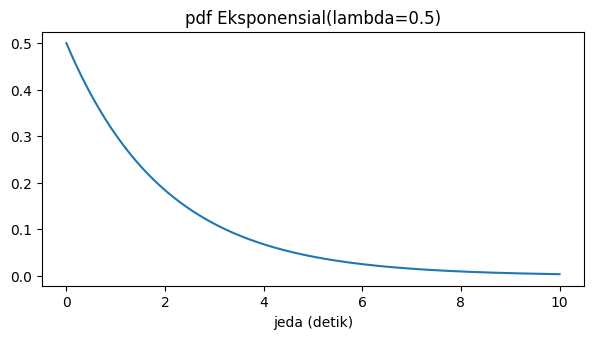

In [15]:
lam = 0.5
ex = stats.expon(scale=1 / lam)
print("P(X>3)       :", round(ex.sf(3), 4), "| manual e^(-1.5) =", round(math.exp(-1.5), 4))
print("P(X<=2)      :", round(ex.cdf(2), 4))
print("Median       :", round(ex.median(), 4), "| 2*ln2 =", round(2 * math.log(2), 4))
print("E, Var       :", ex.mean(), ex.var())
print("Memoryless   : P(X>5 | X>3) =", round(ex.sf(5) / ex.sf(3), 4), "| P(X>2) =", round(ex.sf(2), 4))
print("Hubungan Poisson: P(0 permintaan dalam 3 detik) =", round(stats.poisson.pmf(0, lam * 3), 4))
s = ex.rvs(size=300_000, random_state=5)
print("Simulasi     : mean =", round(s.mean(), 3), "| P(X>3) =", round(np.mean(s > 3), 4))

x = np.linspace(0, 10, 300)
plt.figure(figsize=(7, 3.3)); plt.plot(x, ex.pdf(x)); plt.title("pdf Eksponensial(lambda=0.5)")
plt.xlabel("jeda (detik)"); plt.show()

**Interpretasi:** Peluang jeda lebih dari 3 detik adalah 0,2231 (sekitar 22%), dan 63% jeda berlangsung 2 detik atau kurang. Median jeda (1,39 detik) lebih kecil daripada rata-rata (2 detik) karena distribusi miring ke kanan. Sifat tanpa ingatan terbukti: setelah menunggu 3 detik, peluang menunggu 2 detik lagi tetap 0,1353. Peluang 'tidak ada permintaan selama 3 detik' dari Poisson (0,2231) sama dengan P(jeda > 3), yang menunjukkan eksponensial dan Poisson berasal dari proses yang sama.

## Soal 2.6: Gamma: waktu hingga permintaan ke-3

**Studi kasus:** Dengan laju permintaan yang sama (λ = 0,5 per detik), waktu sampai permintaan ke-3 tiba mengikuti Gamma (r = 3, λ = 0,5).

**Ditanyakan:** Berapa rata-rata, varians, dan P(waktu ≤ 5 detik)? Verifikasi dengan hubungan Poisson: P(T ≤ 5) = P(N ≥ 3), N ~ Poisson(λ·5).

**Konsep / rumus:** E = r/λ = 6; Var = r/λ² = 12.

**Perhitungan manual:** P(N ≥ 3) = 1 − e^(−2,5)(1 + 2,5 + 3,125) = 1 − 0,5438 = 0,4562.

E, Var          : 6.0 12.0
P(T<=5) Gamma   : 0.4562
P(N>=3) Poisson : 0.4562 | sama? True
Simulasi        : mean = 6.007 | var = 12.026 | P(T<=5) = 0.4554


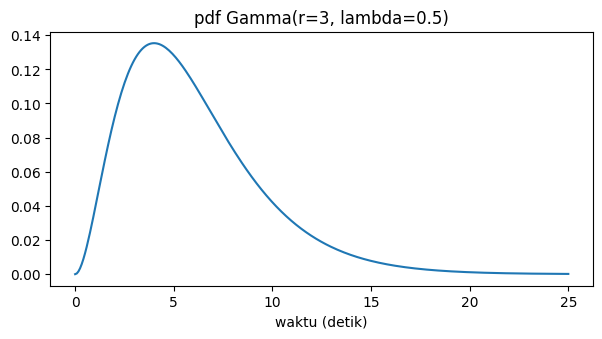

In [16]:
r, lam = 3, 0.5
gm = stats.gamma(a=r, scale=1 / lam)
print("E, Var          :", gm.mean(), gm.var())
p_gamma = gm.cdf(5)
p_poisson = stats.poisson.sf(r - 1, lam * 5)          # P(N >= 3)
print("P(T<=5) Gamma   :", round(p_gamma, 4))
print("P(N>=3) Poisson :", round(p_poisson, 4), "| sama?", np.isclose(p_gamma, p_poisson))
s = gm.rvs(size=300_000, random_state=6)
print("Simulasi        : mean =", round(s.mean(), 3), "| var =", round(s.var(), 3), "| P(T<=5) =", round(np.mean(s <= 5), 4))

x = np.linspace(0, 25, 300)
plt.figure(figsize=(7, 3.3)); plt.plot(x, gm.pdf(x)); plt.title("pdf Gamma(r=3, lambda=0.5)"); plt.xlabel("waktu (detik)"); plt.show()

**Interpretasi:** Rata-rata 6 detik dibutuhkan hingga tiga permintaan tiba (3 kali rata-rata jeda 2 detik), dan peluang tiga permintaan sudah tiba dalam 5 detik adalah 0,4562 (sekitar 46%). Perhitungan lewat distribusi Gamma dan lewat Poisson menghasilkan angka identik, membuktikan keduanya dua sisi dari proses yang sama. Untuk r = 1, Gamma menjadi Eksponensial.

## Soal 2.7: Distribusi t: selang kepercayaan sampel kecil

**Studi kasus:** Waktu muat halaman (detik) diukur 8 kali: 2,1; 2,5; 2,3; 2,8; 2,2; 2,6; 2,4; 2,7. Simpangan baku populasi tidak diketahui.

**Ditanyakan:** Hitung selang kepercayaan 95% untuk rata-rata waktu muat dan bandingkan dengan pendekatan normal. Hitung juga P(T > 2) untuk df = 10.

**Konsep / rumus:** x̄ ± t(0,975; n−1) · s/√n, dengan t berderajat bebas n − 1 = 7.

n=8, rata-rata=2.450, s=0.2449, galat baku=0.0866
t kritis (df=7): 2.3646 | z kritis: 1.96
Selang 95% (t)      : [2.245 2.655]
Selang 95% (normal) : [2.28 2.62] (terlalu sempit)

P(T>2), df=10 : 0.0367 | P(Z>2) normal: 0.0228


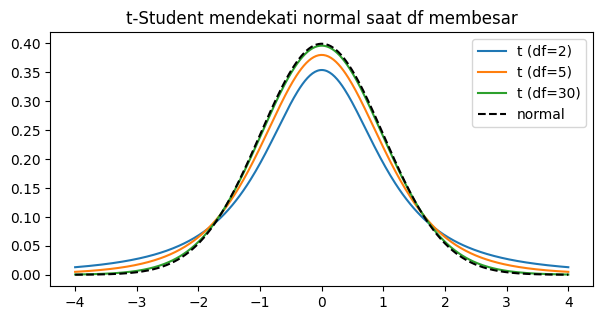

In [17]:
data = np.array([2.1, 2.5, 2.3, 2.8, 2.2, 2.6, 2.4, 2.7])
n = len(data)
xbar, s = data.mean(), data.std(ddof=1)
sem = s / math.sqrt(n)
print(f"n={n}, rata-rata={xbar:.3f}, s={s:.4f}, galat baku={sem:.4f}")

t_krit = stats.t.ppf(0.975, df=n - 1)
print("t kritis (df=7):", round(t_krit, 4), "| z kritis:", round(stats.norm.ppf(0.975), 4))
print("Selang 95% (t)      :", np.round(stats.t.interval(0.95, df=n - 1, loc=xbar, scale=sem), 3))
print("Selang 95% (normal) :", np.round(stats.norm.interval(0.95, loc=xbar, scale=sem), 3), "(terlalu sempit)")
print("\nP(T>2), df=10 :", round(stats.t.sf(2, 10), 4), "| P(Z>2) normal:", round(stats.norm.sf(2), 4))

x = np.linspace(-4, 4, 400)
plt.figure(figsize=(7, 3.3))
for df in [2, 5, 30]:
    plt.plot(x, stats.t.pdf(x, df), label=f"t (df={df})")
plt.plot(x, stats.norm.pdf(x), "k--", label="normal")
plt.legend(); plt.title("t-Student mendekati normal saat df membesar"); plt.show()

**Interpretasi:** Rata-rata waktu muat sampel adalah 2,45 detik, dengan selang kepercayaan 95% sekitar 2,25 sampai 2,65 detik. Distribusi t memberi selang lebih lebar daripada normal karena sampel kecil (n = 8) menambah ketidakpastian pada s; memakai z = 1,96 membuat selang terlalu sempit (terlalu percaya diri). Ekor t lebih tebal: P(T > 2) = 0,0367 dibanding 0,0228 pada normal. Dengan df besar, t hampir sama dengan normal (lihat grafik).

## Soal 2.8: Chi-kuadrat: apakah beban terbagi merata?

**Studi kasus:** Sebanyak 120 permintaan terdistribusi ke 4 server: 35, 28, 30, dan 27. Jika load balancer adil, masing-masing server menerima 30.

**Ditanyakan:** Ujilah pada taraf 5% apakah pembagian beban menyimpang dari merata.

**Konsep / rumus:** χ² = Σ (O − E)² / E dengan df = 4 − 1 = 3. Tolak H₀ jika χ² > nilai kritis.

**Perhitungan manual:** χ² = (25 + 4 + 0 + 9)/30 = 1,2667.

In [18]:
obs = np.array([35, 28, 30, 27])
exp_ = np.full(4, 30)
chi2_hit = ((obs - exp_) ** 2 / exp_).sum()
df = 3
print("Chi-kuadrat hitung :", round(chi2_hit, 4))
print("Nilai kritis (5%)  :", round(stats.chi2.ppf(0.95, df), 4))
print("p-value            :", round(stats.chi2.sf(chi2_hit, df), 4))
hasil = stats.chisquare(obs, exp_)
print("scipy.chisquare    : statistik =", round(float(hasil.statistic), 4), "| p-value =", round(float(hasil.pvalue), 4))

Chi-kuadrat hitung : 1.2667
Nilai kritis (5%)  : 7.8147
p-value            : 0.7371
scipy.chisquare    : statistik = 1.2667 | p-value = 0.7371


**Interpretasi:** Nilai χ² = 1,27 jauh di bawah nilai kritis 7,81 dan p-value ≈ 0,74, sehingga tidak ada bukti bahwa pembagian beban menyimpang dari merata; selisih 35 vs 27 masih wajar akibat kebetulan. Hasil hitungan manual sama dengan `scipy.stats.chisquare`. Catatan: gagal menolak H₀ bukan bukti bahwa beban pasti merata, hanya bahwa data tidak cukup untuk menyimpulkan sebaliknya.

## Soal 2.9: Distribusi F: membandingkan variansi dua algoritma

**Studi kasus:** Waktu eksekusi algoritma A diukur 10 kali dengan varians sampel 4,5 ms²; algoritma B diukur 12 kali dengan varians 2,0 ms².

**Ditanyakan:** Apakah varians A lebih besar daripada B secara signifikan pada taraf 5% (uji satu sisi)?

**Konsep / rumus:** F = s²_A / s²_B dengan df₁ = 9 dan df₂ = 11.

**Perhitungan manual:** F = 4,5 / 2,0 = 2,25.

In [19]:
sA2, nA = 4.5, 10
sB2, nB = 2.0, 12
F = sA2 / sB2
d1, d2 = nA - 1, nB - 1
print("F hitung     :", round(F, 4))
print("F kritis 5%  :", round(stats.f.ppf(0.95, d1, d2), 4))
print("p-value      :", round(stats.f.sf(F, d1, d2), 4))

F hitung     : 2.25
F kritis 5%  : 2.8962
p-value      : 0.1028


**Interpretasi:** F hitung 2,25 lebih kecil dari nilai kritis 2,90 dan p-value sekitar 0,10 (di atas 0,05), sehingga belum cukup bukti bahwa variasi waktu eksekusi A lebih besar daripada B. Walaupun varians sampel A lebih dari dua kali varians B, ukuran sampel kecil membuat perbedaan itu masih bisa terjadi karena kebetulan. Menambah jumlah pengukuran akan membuat uji lebih peka.

## Soal 2.10: Beta: memperbarui keyakinan tentang tingkat konversi

**Studi kasus:** Prior tingkat konversi sebuah halaman web adalah Beta(2, 8) (rata-rata 0,2). Setelah 100 kunjungan terdapat 30 konversi.

**Ditanyakan:** Berapa rata-rata posterior dan selang kredibel 95% untuk tingkat konversi?

**Konsep / rumus:** Posterior = Beta(a + sukses, b + gagal) = Beta(32, 78). E = a/(a+b).

**Perhitungan manual:** Rata-rata posterior = 32/110 ≈ 0,2909.

Rata-rata prior     : 0.2
Rata-rata posterior : 0.2909 | manual 32/110 = 0.2909
Selang kredibel 95% : [0.2102 0.3788]
Data mentah 30/100  : 0.3


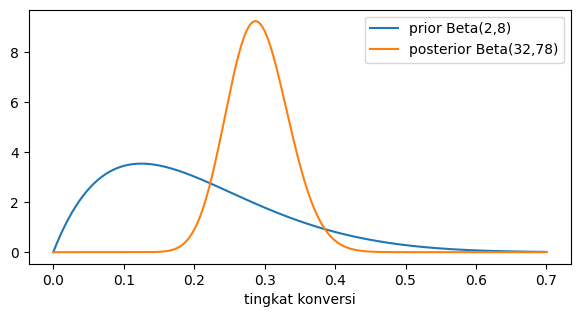

In [20]:
a0, b0 = 2, 8
sukses, gagal = 30, 70
post = stats.beta(a0 + sukses, b0 + gagal)
prior = stats.beta(a0, b0)
print("Rata-rata prior     :", round(prior.mean(), 4))
print("Rata-rata posterior :", round(post.mean(), 4), "| manual 32/110 =", round(32 / 110, 4))
print("Selang kredibel 95% :", np.round(post.interval(0.95), 4))
print("Data mentah 30/100  :", 30 / 100)

x = np.linspace(0, 0.7, 400)
plt.figure(figsize=(7, 3.3))
plt.plot(x, prior.pdf(x), label="prior Beta(2,8)")
plt.plot(x, post.pdf(x), label="posterior Beta(32,78)")
plt.xlabel("tingkat konversi"); plt.legend(); plt.show()

**Interpretasi:** Rata-rata posterior 0,291 berada di antara prior (0,20) dan data mentah (0,30), lebih dekat ke data karena 100 kunjungan lebih informatif daripada prior setara 10 pengamatan. Selang kredibel 95% kira-kira 0,21 sampai 0,38, artinya tingkat konversi sebenarnya dengan peluang 95% berada pada rentang itu. Kurva posterior lebih sempit daripada prior, menandakan ketidakpastian berkurang setelah ada data.

## Soal 2.11: Log-normal: ukuran file unggahan

**Studi kasus:** Ukuran file unggahan (KB) berdistribusi log-normal, yaitu logaritma alami ukuran berdistribusi normal dengan μ = 4,6 dan σ = 0,8.

**Ditanyakan:** Hitung median, rata-rata, dan P(ukuran > 300 KB).

**Konsep / rumus:** Median = e^μ; E = e^(μ + σ²/2). Dalam scipy: `lognorm(s=σ, scale=exp(μ))`.

**Perhitungan manual:** Median = e^4,6 ≈ 99,5 KB; E = e^4,92 ≈ 137,0 KB.

In [21]:
mu_l, sg_l = 4.6, 0.8
ln = stats.lognorm(s=sg_l, scale=math.exp(mu_l))
print("Median            :", round(ln.median(), 2), "KB | e^mu =", round(math.exp(mu_l), 2))
print("Rata-rata         :", round(ln.mean(), 2), "KB | e^(mu+s^2/2) =", round(math.exp(mu_l + sg_l**2 / 2), 2))
print("P(ukuran > 300 KB):", round(ln.sf(300), 4))
print("Persentil ke-95   :", round(ln.ppf(0.95), 1), "KB")

Median            : 99.48 KB | e^mu = 99.48
Rata-rata         : 137.0 KB | e^(mu+s^2/2) = 137.0
P(ukuran > 300 KB): 0.0838
Persentil ke-95   : 370.9 KB


**Interpretasi:** Median ukuran file sekitar 99,5 KB, sedangkan rata-ratanya 137 KB; rata-rata lebih besar karena ekor kanan yang panjang (sedikit file sangat besar menarik rata-rata ke atas). Sekitar 8% file lebih besar dari 300 KB. Karena distribusinya miring, kapasitas penyimpanan sebaiknya direncanakan dengan persentil (95% file ≤ sekitar 371 KB), bukan hanya rata-rata.

## Soal 2.12: Weibull: umur hard disk

**Studi kasus:** Umur hard disk (jam) mengikuti Weibull dengan bentuk c = 1,5 dan skala 1.000 jam (c > 1 berarti laju kerusakan meningkat seiring usia).

**Ditanyakan:** Berapa peluang disk bertahan lebih dari 1.000 jam, rata-rata umur, dan umur median?

**Konsep / rumus:** P(X > x) = exp(−(x/skala)ᶜ); E = skala · Γ(1 + 1/c).

**Perhitungan manual:** P(X > 1.000) = e^(−1) = 0,3679.

In [22]:
c, skala = 1.5, 1000
wb = stats.weibull_min(c, scale=skala)
print("P(X>1000 jam) :", round(wb.sf(1000), 4), "| e^-1 =", round(math.exp(-1), 4))
print("Rata-rata     :", round(wb.mean(), 1), "jam | skala*Gamma(1+1/c) =", round(skala * math.gamma(1 + 1 / c), 1))
print("Median        :", round(wb.median(), 1), "jam")
print("P(rusak < 200 jam):", round(wb.cdf(200), 4))

P(X>1000 jam) : 0.3679 | e^-1 = 0.3679
Rata-rata     : 902.7 jam | skala*Gamma(1+1/c) = 902.7
Median        : 783.2 jam
P(rusak < 200 jam): 0.0856


**Interpretasi:** Hanya sekitar 36,8% disk bertahan lebih dari 1.000 jam; rata-rata umur 902,7 jam dan median 783 jam. Karena c > 1, risiko rusak naik seiring usia (fase aus), sehingga penggantian terjadwal sebelum umur tertentu masuk akal. Sekitar 8,6% disk rusak sebelum 200 jam, yang bisa dipakai untuk menaksir klaim garansi awal.

## Kesimpulan Bab 2

Distribusi kontinu dipilih berdasarkan sifat data: simetris (Normal), jeda atau umur (Eksponensial, Gamma, Weibull), data positif miring (Log-normal), peluang 0–1 (Beta), serta distribusi turunan untuk inferensi (t, Chi-kuadrat, F). Pada setiap soal, hasil dihitung dengan `scipy.stats` dan, bila memungkinkan, dibandingkan dengan rumus manual atau simulasi.

---
# Bab 3: Variabel Acak, Teorema Limit Pusat, dan Aproksimasi Distribusi

Isi: distribusi gabungan dua variabel acak (kovarians dan korelasi), aproksimasi Binomial ke Normal dan ke Poisson, Teorema Limit Pusat (CLT), serta ketidaksamaan Chebyshev.

## Pengertian singkat

- **Distribusi gabungan** P(X = x, Y = y) memuat peluang dua variabel acak sekaligus; **marginal** diperoleh dengan menjumlahkan baris atau kolom.
- **Kovarians:** Cov(X,Y) = E(XY) − E(X)E(Y); **korelasi:** ρ = Cov / (σₓσᵧ), nilainya antara −1 dan 1.
- **Aproksimasi Binomial → Normal** (n besar, np ≥ 5 dan n(1−p) ≥ 5) memakai koreksi kontinuitas ±0,5.
- **Binomial → Poisson** (n besar, p kecil) dengan λ = np.
- **CLT:** rata-rata sampel acak berukuran besar mendekati normal dengan rata-rata μ dan simpangan baku σ/√n, apa pun bentuk distribusi asalnya.
- **Chebyshev:** P(|X − μ| ≥ kσ) ≤ 1/k² untuk distribusi apa pun.

In [23]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
rng = np.random.default_rng(42)

## Soal 3.1: Distribusi gabungan, marginal, kovarians, dan korelasi

**Studi kasus:** Dalam satu rilis perangkat lunak, X = jumlah bug kritis (0, 1, 2) dan Y = jumlah test case gagal (0, 1, 2). Distribusi gabungannya:

| | Y=0 | Y=1 | Y=2 |
|---|---|---|---|
| X=0 | 0,30 | 0,10 | 0,02 |
| X=1 | 0,10 | 0,20 | 0,08 |
| X=2 | 0,02 | 0,08 | 0,10 |

**Ditanyakan:** Tentukan marginal, E(X), Var(X), Cov(X,Y), korelasi, dan P(Y=0 ∣ X=0). Apakah X dan Y independen?

**Konsep / rumus:** Cov = E(XY) − E(X)E(Y); independen jika P(x,y) = P(x)P(y) untuk semua sel.

**Perhitungan manual:** E(X) = 0,78; E(X²) = 1,18; Var(X) = 1,18 − 0,6084 = 0,5716; E(XY) = 0,92; Cov = 0,92 − 0,6084 = 0,3116; ρ = 0,3116/0,5716 ≈ 0,545.

In [24]:
J = np.array([[0.30, 0.10, 0.02],
              [0.10, 0.20, 0.08],
              [0.02, 0.08, 0.10]])
vals = np.array([0, 1, 2])
print("Jumlah seluruh sel:", round(J.sum(), 2))

pX, pY = J.sum(axis=1), J.sum(axis=0)
print("Marginal X:", pX, "| Marginal Y:", pY)

EX, EY = (vals * pX).sum(), (vals * pY).sum()
VarX = ((vals**2) * pX).sum() - EX**2
VarY = ((vals**2) * pY).sum() - EY**2
EXY = sum(i * j * J[a, b] for a, i in enumerate(vals) for b, j in enumerate(vals))
cov = EXY - EX * EY
rho = cov / math.sqrt(VarX * VarY)
print(f"E(X)={EX:.2f}, Var(X)={VarX:.4f}, E(XY)={EXY:.2f}, Cov={cov:.4f}, korelasi={rho:.4f}")
print("P(Y=0 | X=0) =", round(J[0, 0] / pX[0], 4), "| P(Y=0) =", round(pY[0], 2))
print("Independen? P(0,0) =", J[0, 0], "vs P(X=0)P(Y=0) =", round(pX[0] * pY[0], 4))

# simulasi
idx = rng.choice(9, size=300_000, p=J.ravel())
X, Y = vals[idx // 3], vals[idx % 3]
print("Simulasi: cov =", round(np.cov(X, Y)[0, 1], 4), "| korelasi =", round(np.corrcoef(X, Y)[0, 1], 4))

Jumlah seluruh sel: 1.0
Marginal X: [0.42 0.38 0.2 ] | Marginal Y: [0.42 0.38 0.2 ]
E(X)=0.78, Var(X)=0.5716, E(XY)=0.92, Cov=0.3116, korelasi=0.5451
P(Y=0 | X=0) = 0.7143 | P(Y=0) = 0.42
Independen? P(0,0) = 0.3 vs P(X=0)P(Y=0) = 0.1764
Simulasi: cov = 0.3121 | korelasi = 0.5456


**Interpretasi:** Kovarians positif (0,3116) dan korelasi sekitar 0,55 menunjukkan hubungan positif sedang: rilis dengan lebih banyak bug kritis cenderung punya lebih banyak test gagal. Jika tidak ada bug kritis (X = 0), peluang tidak ada test gagal adalah 0,714, jauh di atas peluang tanpa syarat 0,42, jadi X dan Y tidak independen (juga terlihat dari P(0,0) = 0,30 ≠ 0,1764). Korelasi bukan bukti sebab-akibat; keduanya bisa dipengaruhi faktor ketiga (misalnya kompleksitas kode). Simulasi mengonfirmasi angka kovarians dan korelasi.

## Soal 3.2: Aproksimasi Binomial dengan Normal

**Studi kasus:** Dari 50 permintaan, tiap permintaan gagal dengan peluang 0,25. X = jumlah permintaan gagal.

**Ditanyakan:** Hitung P(X ≤ 15) secara eksak (binomial) dan dengan aproksimasi normal (dengan dan tanpa koreksi kontinuitas).

**Konsep / rumus:** X ≈ Normal(μ = np, σ² = np(1−p)); dengan koreksi: P(X ≤ 15) ≈ P(Y ≤ 15,5).

**Perhitungan manual:** μ = 12,5; σ² = 9,375; σ ≈ 3,062; z = (15,5 − 12,5)/3,062 ≈ 0,98.

Syarat: np = 12.5 | n(1-p) = 37.5 (keduanya >= 5)
Eksak (binomial)              : 0.8369
Normal dengan koreksi (15.5)  : 0.8364 | galat: 0.0005
Normal tanpa koreksi (15)     : 0.7929 | galat: 0.044


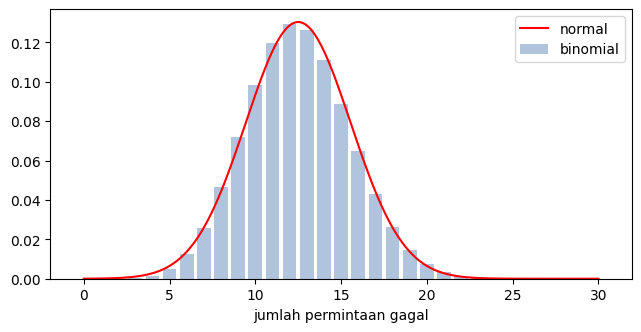

In [25]:
n, p = 50, 0.25
mu_b, sd_b = n * p, math.sqrt(n * p * (1 - p))
print("Syarat: np =", n * p, "| n(1-p) =", n * (1 - p), "(keduanya >= 5)")

eksak = stats.binom.cdf(15, n, p)
norm_cc = stats.norm.cdf(15.5, mu_b, sd_b)
norm_tanpa = stats.norm.cdf(15, mu_b, sd_b)
print("Eksak (binomial)              :", round(eksak, 4))
print("Normal dengan koreksi (15.5)  :", round(norm_cc, 4), "| galat:", round(abs(norm_cc - eksak), 4))
print("Normal tanpa koreksi (15)     :", round(norm_tanpa, 4), "| galat:", round(abs(norm_tanpa - eksak), 4))

x = np.arange(0, 31)
plt.figure(figsize=(7.5, 3.5))
plt.bar(x, stats.binom.pmf(x, n, p), color="lightsteelblue", label="binomial")
xx = np.linspace(0, 30, 300)
plt.plot(xx, stats.norm.pdf(xx, mu_b, sd_b), "r", label="normal")
plt.legend(); plt.xlabel("jumlah permintaan gagal"); plt.show()

**Interpretasi:** Peluang paling banyak 15 dari 50 permintaan gagal adalah sekitar 0,84. Aproksimasi normal dengan koreksi kontinuitas jauh lebih dekat ke nilai eksak daripada tanpa koreksi (lihat galat pada output), karena distribusi diskrit didekati oleh kurva kontinu. Aproksimasi layak dipakai karena syarat np ≥ 5 dan n(1−p) ≥ 5 terpenuhi, dan grafik memperlihatkan kurva menempel pada batang binomial.

## Soal 3.3: Aproksimasi Binomial dengan Poisson

**Studi kasus:** Sebuah sistem memproses 1.000 transaksi; tiap transaksi bermasalah dengan peluang 0,002 (kejadian langka).

**Ditanyakan:** Bandingkan P(X = x) binomial dengan Poisson(λ = np = 2) untuk x = 0 sampai 6.

**Konsep / rumus:** Binomial(n, p) ≈ Poisson(λ = np) bila n besar dan p kecil.

In [26]:
n, p = 1000, 0.002
x = np.arange(0, 7)
tabel = pd.DataFrame({"x": x, "binomial": stats.binom.pmf(x, n, p).round(5),
                      "poisson": stats.poisson.pmf(x, n * p).round(5)})
tabel["selisih"] = (tabel["binomial"] - tabel["poisson"]).abs().round(5)
print(tabel.to_string(index=False))
print("Selisih terbesar:", tabel["selisih"].max())
print("P(X>=5) binomial :", round(stats.binom.sf(4, n, p), 5), "| Poisson:", round(stats.poisson.sf(4, n * p), 5))

 x  binomial  poisson  selisih
 0   0.13506  0.13534  0.00028
 1   0.27067  0.27067  0.00000
 2   0.27094  0.27067  0.00027
 3   0.18063  0.18045  0.00018
 4   0.09022  0.09022  0.00000
 5   0.03602  0.03609  0.00007
 6   0.01197  0.01203  0.00006
Selisih terbesar: 0.00028
P(X>=5) binomial : 0.05247 | Poisson: 0.05265


**Interpretasi:** Peluang tepat 2 transaksi bermasalah adalah sekitar 0,27 pada kedua distribusi, dan selisih terbesar antar keduanya sangat kecil (di bawah 0,001). Karena itu untuk kejadian langka dengan n besar, Poisson cukup dan lebih mudah dihitung. Bila p tidak kecil (misalnya 0,3), pendekatan ini tidak layak dan harus memakai binomial.

## Soal 3.4: Teorema Limit Pusat: rata-rata waktu respons

**Studi kasus:** Waktu pemrosesan satu permintaan berdistribusi eksponensial (sangat miring) dengan rata-rata 2 detik dan simpangan baku 2 detik. Dihitung rata-rata dari n permintaan untuk n = 1, 5, 30, 100.

**Ditanyakan:** Bagaimana bentuk distribusi rata-rata sampel? Berapa peluang rata-rata dari 100 permintaan melebihi 2,4 detik?

**Konsep / rumus:** Rata-rata sampel ≈ Normal(μ, σ²/n). Untuk n = 100: galat baku = 2/√100 = 0,2; P(X̄ > 2,4) ≈ P(Z > 2) = 0,0228.

   n | rata-rata sampel | simpangan baku | teori sigma/sqrt(n) | skewness
   1 |            1.965 |          1.950 |               2.000 |    2.040
   5 |            2.000 |          0.885 |               0.894 |    0.861
  30 |            2.001 |          0.362 |               0.365 |    0.371
 100 |            1.999 |          0.199 |               0.200 |    0.207


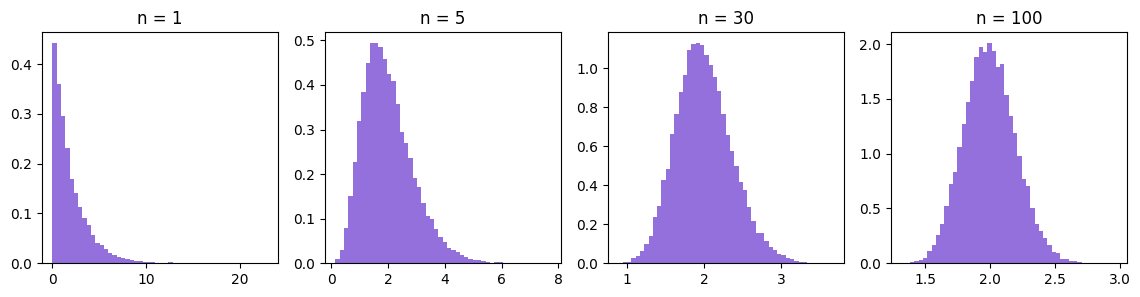


P(rata-rata > 2.4), aproksimasi normal: 0.0228
P(rata-rata > 2.4), simulasi          : 0.0281


In [27]:
mu_e, sg_e = 2.0, 2.0
fig, axs = plt.subplots(1, 4, figsize=(14, 3))
print("   n | rata-rata sampel | simpangan baku | teori sigma/sqrt(n) | skewness")
for ax, n in zip(axs, [1, 5, 30, 100]):
    rata = rng.exponential(mu_e, size=(20_000, n)).mean(axis=1)
    print(f"{n:>4} | {rata.mean():>16.3f} | {rata.std():>14.3f} | {sg_e / math.sqrt(n):>19.3f} | {stats.skew(rata):>8.3f}")
    ax.hist(rata, bins=50, density=True, color="mediumpurple")
    ax.set_title(f"n = {n}")
plt.show()

n = 100
rata = rng.exponential(mu_e, size=(100_000, n)).mean(axis=1)
print("\nP(rata-rata > 2.4), aproksimasi normal:", round(stats.norm.sf(2.4, mu_e, sg_e / math.sqrt(n)), 4))
print("P(rata-rata > 2.4), simulasi          :", round(np.mean(rata > 2.4), 4))

**Interpretasi:** Untuk n = 1 distribusi sangat miring (skewness ≈ 2), tetapi semakin besar n bentuknya makin simetris dan menyerupai lonceng, dengan simpangan baku menyusut mengikuti σ/√n. Peluang rata-rata dari 100 permintaan melebihi 2,4 detik hanya sekitar 2 hingga 3% menurut kedua cara (aproksimasi normal 0,0228; simulasi sedikit lebih besar karena distribusi asal masih miring). Dalam praktik TI, CLT membenarkan pemakaian uji berbasis normal pada rata-rata metrik performa meskipun data mentah tidak normal, asalkan sampelnya cukup besar.

## Soal 3.5: Ketidaksamaan Chebyshev

**Studi kasus:** Waktu respons API Normal(12 ms, 3² ms²), seperti pada Soal 2.2 (Normal).

**Ditanyakan:** Bandingkan batas atas Chebyshev untuk P(|X − μ| ≥ kσ) dengan peluang sebenarnya pada distribusi normal untuk k = 1,5; 2; 3.

**Konsep / rumus:** Chebyshev: P(|X − μ| ≥ kσ) ≤ 1/k² (berlaku untuk distribusi apa pun).

In [28]:
tabel = []
for k in [1.5, 2, 3]:
    batas = 1 / k**2
    sebenarnya = 2 * stats.norm.sf(k)
    tabel.append((k, round(batas, 4), round(sebenarnya, 4)))
print(pd.DataFrame(tabel, columns=["k", "batas Chebyshev", "peluang sebenarnya (normal)"]).to_string(index=False))

  k  batas Chebyshev  peluang sebenarnya (normal)
1.5           0.4444                       0.1336
2.0           0.2500                       0.0455
3.0           0.1111                       0.0027


**Interpretasi:** Batas Chebyshev selalu lebih besar dari peluang sebenarnya pada distribusi normal (misalnya k = 2: batas 0,25 vs sebenarnya 0,0455), jadi batasnya benar tetapi longgar. Keunggulannya berlaku untuk distribusi apa pun, sehingga berguna ketika bentuk distribusi data tidak diketahui; bila distribusi normal diketahui, perhitungan langsung jauh lebih tajam.

## Kesimpulan Bab 3

Variabel acak gabungan menjelaskan hubungan antar variabel lewat kovarians dan korelasi. Aproksimasi (Binomial ke Normal/Poisson) mempermudah perhitungan bila syaratnya terpenuhi, CLT menjelaskan mengapa distribusi normal begitu sering muncul pada rata-rata, dan Chebyshev memberi batas aman tanpa mengetahui bentuk distribusi.